# Homework 5

## 1 - Gradient descent and backpropagation in a simple neural network

## 2 - Neural networks for a regression task using scikit-learn

### 2.1 - Loading the diabetes dataset

In [27]:
from sklearn.datasets import load_diabetes
import numpy as np

X, y = load_diabetes(return_X_y=True, scaled=False) # I am going to scale them myself later
feature_names = ["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]

print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

Shape of X: (442, 10)
Shape of y: (442,)


We have 442 samples with 10 features and 1 label each.  
From reading online the features are: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6.  
The label is a measure of disease, numbers are between 25 and 346.

### 2.2 - Visualizing the data

I will create a scatterplot for each feature with the target. This will hopefully show me what features are relevant for the target.

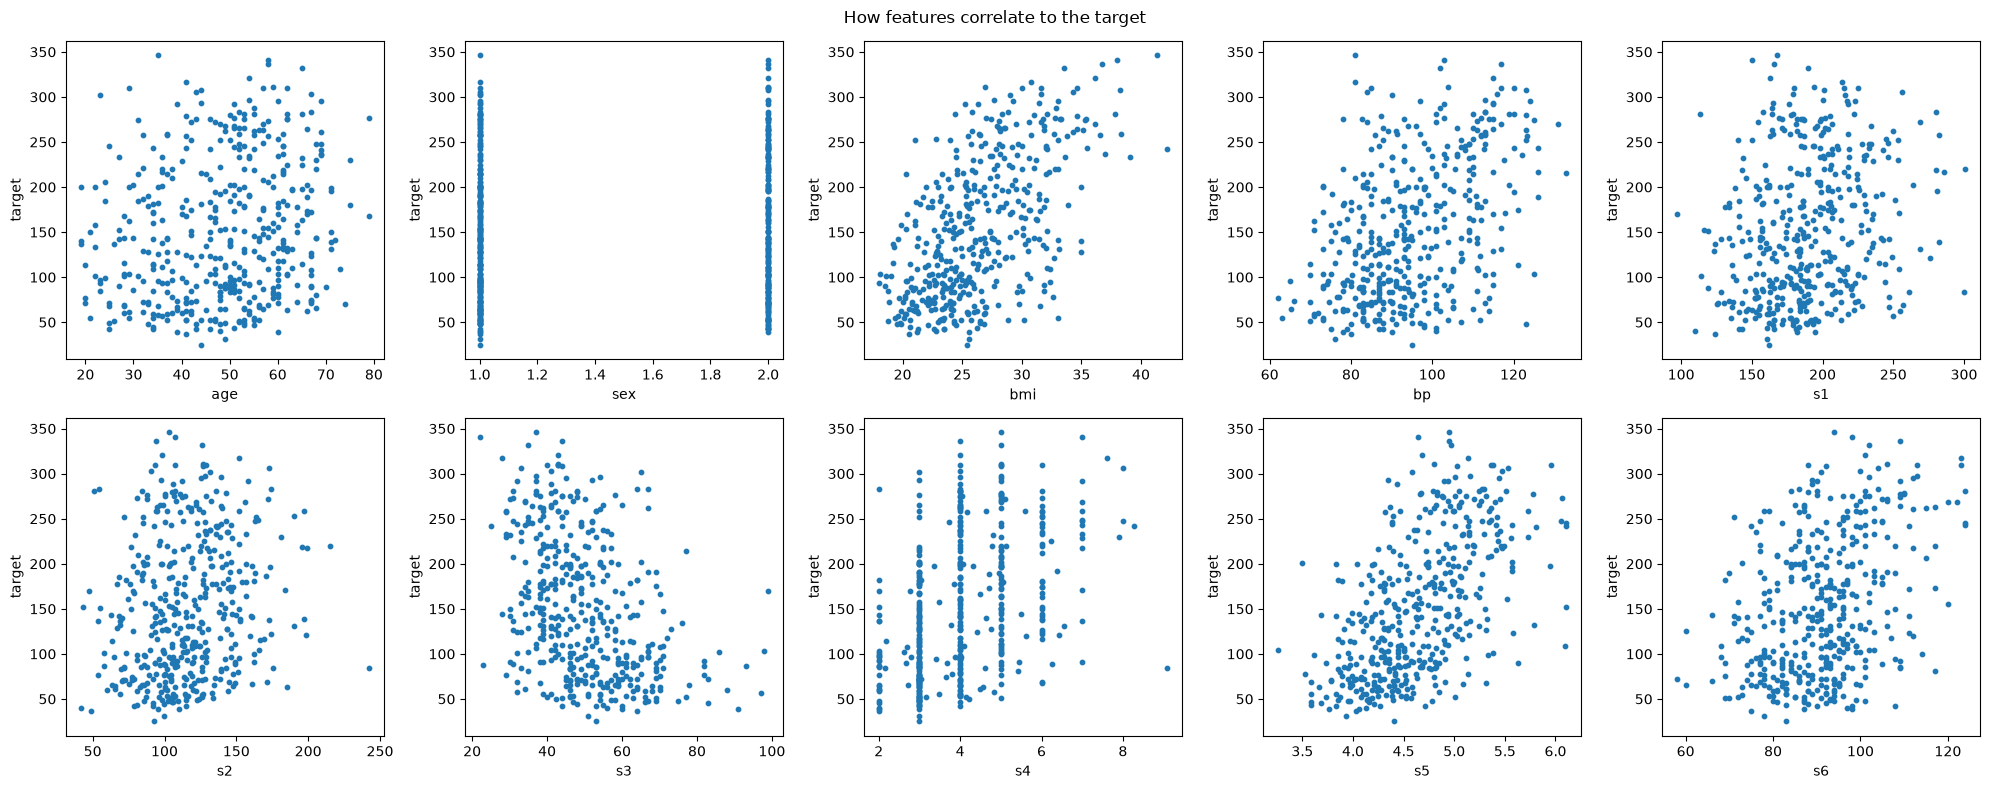

In [28]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 5, figsize=(20, 8))

fig.suptitle("How features correlate to the target")
for i, ax in enumerate(axs.flat):
    ax.scatter(X[:, i], y, s=10)
    ax.set_xlabel(feature_names[i])
    ax.set_ylabel("target")
plt.tight_layout()
plt.show()

### 2.3 - Preprocessing the data

#### (a) Selecting relevant features
It looks to me like the most relevant features are bmi, bp, s3, s4 and s5. I will therefore drop age, sex, s1, s2 and s6.

In [29]:
relevant = [2, 3, 6, 7, 8]
X_relevant = X[:, relevant]
feature_names_relevant = [feature_names[i] for i in relevant]

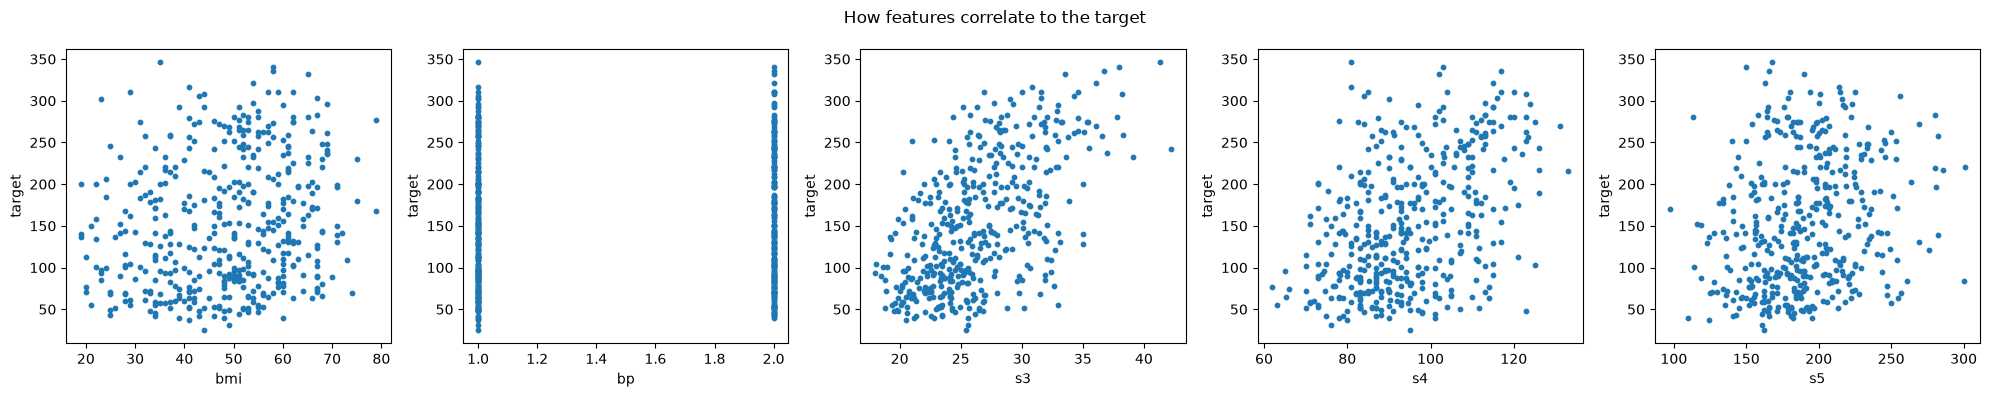

In [30]:
fig, axs = plt.subplots(1, 5, figsize=(20, 4))

fig.suptitle("How features correlate to the target")
for i, ax in enumerate(axs.flat):
    ax.scatter(X[:, i], y, s=10)
    ax.set_xlabel(feature_names_relevant[i])
    ax.set_ylabel("target")
plt.tight_layout()
plt.show()

#### (b) Splitting the data into training, validation and testing

In [31]:
from sklearn.model_selection import train_test_split

seed = 67

X_train, X_test, y_train, y_test = train_test_split(X_relevant, y, test_size=0.15, random_state=seed)

#### (c) Scaling the data

I will be scaling the data using the StandardScaler which centres values around 0 with a standard deviation of 1. I will do this in a pipeline.

### 2.4 - Building simple MLPs

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPRegressor(random_state=seed, max_iter=2000))
])

param_grid = {
    "model__hidden_layer_sizes": [(8, 4, 2)],
    "model__activation": ["identity", "logistic", "tanh", "relu"],
    "model__solver": ["lbfgs", "adam"],
    "model__alpha": [0.1]

}

### 2.5 - Training the models with MSE

In [33]:
grid_searh = GridSearchCV(estimator=pipeline, param_grid=param_grid, scoring="neg_mean_squared_error", cv=5, refit=True)
grid_searh.fit(X_train, y_train)

print(grid_searh.best_params_)
print(grid_searh.best_score_)

c:\Users\Magnus\Desktop\inf264\homework5\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\Magnus\Desktop\inf264\homework5\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_

{'model__activation': 'identity', 'model__alpha': 0.01, 'model__hidden_layer_sizes': (32, 16, 8), 'model__solver': 'adam'}
-3201.7433632497678


c:\Users\Magnus\Desktop\inf264\homework5\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
